In [2]:
from sentence_transformers import SentenceTransformer
import numpy as np

c:\Users\danni\anaconda3\envs\psi\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 857.81it/s]


In [4]:
aliceData = []
with open("Datasets/ENCRYPTO/emails_alice.txt", "r") as f:
    for line in f:
        aliceData.append(line.strip())

In [5]:
bobData = []
with open("Datasets/ENCRYPTO/emails_bob.txt", "r") as f:
    for line in f:
        bobData.append(line.strip())

In [6]:
Intersection = [val for val in aliceData if val in bobData ]
Intersection

['Michael.Zohner@ec-spride.de',
 'Evelyne.Wagener@tvcablenet.be',
 'Ivonne.Pfisterer@mail.ru']

In [7]:
aliceIndex = []
bobIndex = []
for val in Intersection:
    aliceIndex.append(aliceData.index(val))
    bobIndex.append(bobData.index(val))

print(aliceIndex)
print(bobIndex)

[0, 1, 182]
[0, 1, 432]


In [8]:
intersectionEmbedding = model.encode(Intersection)

In [9]:
embeddingAlice = model.encode(aliceData)
embeddingBob = model.encode(bobData)

In [10]:
import matplotlib.pyplot as plt

In [11]:
allDistances = embeddingAlice @ embeddingBob.T

col_indices = np.argmax(allDistances, axis=1)


maxSim = []
for i, c in enumerate(col_indices):
    distance = allDistances[i, c]

    print("current data distance:", i, c, distance)
    maxSim.append(distance)


current data distance: 0 0 0.99999976
current data distance: 1 1 1.0000004
current data distance: 2 368 0.8716129
current data distance: 3 553 0.79595435
current data distance: 4 122 0.69323707
current data distance: 5 917 0.7406036
current data distance: 6 540 0.7313939
current data distance: 7 551 0.7466842
current data distance: 8 638 0.83742076
current data distance: 9 109 0.6534346
current data distance: 10 448 0.7066096
current data distance: 11 143 0.72071636
current data distance: 12 10 0.69963115
current data distance: 13 615 0.79839116
current data distance: 14 780 0.7068872
current data distance: 15 237 0.74719125
current data distance: 16 466 0.74487877
current data distance: 17 847 0.89411277
current data distance: 18 4 0.6115747
current data distance: 19 511 0.8754806
current data distance: 20 457 0.7684439
current data distance: 21 295 0.7530789
current data distance: 22 900 0.63011974
current data distance: 23 948 0.59673715
current data distance: 24 815 0.6943912
curre

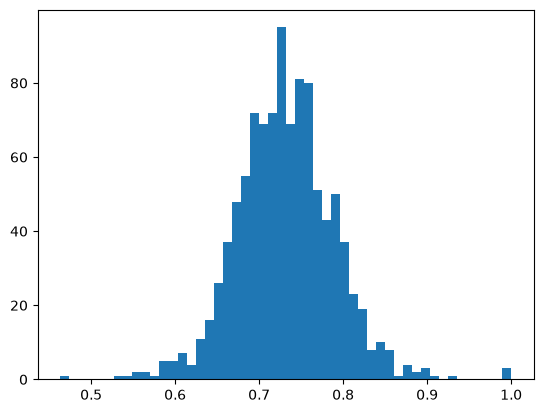

In [12]:
plt.hist(maxSim, bins=50)
plt.show()

### Encryption Comparisons



In [99]:
def inspect_transparency(enc_vector):
    ciphertexts = enc_vector.ciphertext()

    for i, ct in enumerate(ciphertexts):
        if hasattr(ct, "is_transparent"):
            print(f"Ciphertext {i}: {ct.is_transparent()}")
        else:
            print("Transparency API not exposed in this build")

In [98]:
numSamples = 10000
numDims = 10
zero_vector = [0.0] * numDims

zero_ciphertexts = [
    ts.ckks_vector(context, zero_vector)
    for _ in range(numSamples)
]

data_ciphertexts = [
    ts.ckks_vector(context, np.random.randint(0, 5, size=numDims))
        for _ in range(numSamples)
]

In [ ]:
X_zero = [ct.serialize() for ct in zero_ciphertexts]
X_data = [ct.serialize() for ct in data_ciphertexts]
y_zero = np.zeros(len(X_zero), dtype=int)
y_data = np.ones(len(X_data), dtype=int)

X = X_zero + X_data
y = np.concatenate([y_zero, y_data])

print("Total samples:", len(X))
print("Zero samples:", sum(y == 0))
print("Nonzero samples:", sum(y == 1))

Total samples: 20000
Zero samples: 10000
Nonzero samples: 10000


In [107]:
len(X_zero[0])

330811

In [104]:
testCipherText = zero_ciphertexts[0].ciphertext()
for ct in testCipherText:
    print("Polynomial components:", ct.size())
    print("Polynomial degree:", ct.poly_modulus_degree())

Polynomial components: 2
Polynomial degree: 8192


## Computing test with ckks encryption using tenseal library


There are 1024 items in the sets to be encrypted and psi matched

In [13]:
import tenseal as ts
from time import time

In [26]:
startKeyGeneration = time()

# Create CKKS encryption context
context = ts.context(
    ts.SCHEME_TYPE.CKKS,
    poly_modulus_degree=8192,
    coeff_mod_bit_sizes=[60, 40, 40, 60]
)

context.global_scale = 2**40
context.generate_galois_keys()

enc_1 = ts.ckks_vector(context, np.array([1]))
enc_0 = ts.ckks_vector(context, np.array([0]))

endKeyGeneration = time()

print("key gen time ", endKeyGeneration - startKeyGeneration)

key gen time  0.36237454414367676


In [59]:
numSamples = embeddingAlice.shape[0]
numDim = embeddingAlice.shape[1]
numSamples

1024

In [24]:
encryptedAlice = []
encryptionTimeAlice = []

for i in range(numSamples):
    startAEncrypt = time()

    enc_a = ts.ckks_vector(context, embeddingAlice[i])
    encryptedAlice.append(enc_a)

    endAEncrypt = time()

    encryptionTime = endAEncrypt - startAEncrypt
    encryptionTimeAlice.append(encryptionTime)

print("time for A to encrypt", sum(encryptionTimeAlice))

time for A to encrypt 5.211400032043457


In [25]:
encryptedBob = []
encryptionTimeBob = []

for i in range(numSamples):
    startBEncrypt = time()

    enc_b = ts.ckks_vector(context, embeddingBob[i])
    encryptedBob.append(enc_b) 

    endBEncrypt = time()

    encryptionTime = endBEncrypt - startBEncrypt
    encryptionTimeBob.append(encryptionTime)

print("time for B to encrypt", sum(encryptionTimeBob))

time for B to encrypt 6.063405275344849


In [30]:
start = time()
encryptedAlice[0].dot(encryptedBob[0])
end = time()

print(end - start)

0.04166698455810547


In [50]:
from rapidfuzz.distance import Levenshtein

a = b"hello"
b = b"hallo"

distance = Levenshtein.distance(a, b)

print("Edit distance:", distance)

Edit distance: 1


In [54]:
start = time()
res = encryptedAlice[0] - encryptedBob[0]
finalDist = res.dot(res)
dec_res = finalDist.decrypt()
print(dec_res)
end = time()
print(end - start)

[-9.34385309671006e-07]
0.0524137020111084


In [64]:
start = time()
res = encryptedAlice[0].dot(encryptedBob[0])
dec_res = finalDist.decrypt()
print(dec_res)
end = time()
print(end - start)

[-1.0035071415546972e-05]
0.039556026458740234


In [62]:
rng = np.random.default_rng()
weights = rng.integers(1, 257, size=numDim).astype(float).tolist()


In [63]:
start = time()
res = encryptedAlice[0] - encryptedBob[0]
finalDist = res.dot(weights)
dec_res = finalDist.decrypt()
print(dec_res)
end = time()
print(end - start)


[-1.0035071415546972e-05]
0.031157732009887695


In [66]:
def subtractionRandomSum(enc_a, enc_b, randVec):
    tempDiff = enc_a - enc_b
    res = tempDiff.dog(randVec)
    return res

In [ ]:
start_subtraction_comparison = time()

index_alice = []
knowledge_bob = []
for i in range(10):
    currentDistance = []
    a_query = encryptedAlice[i]
    for j in range(10):
        b_vec = encryptedBob[j]
        distance = a_query.dot(b_vec)
        if distance == enc_1:
            index_alice.append(i)
            knowledge_bob.append(j)

print(index_alice)

end_subtraction_comaprison = time()

ComparisonTime = endComparison - startCompariosn

In [89]:
result = []
for i in range(10):
    aliceVec = embeddingAlice[i]
    for j in range(10):
        bobVec = embeddingBob[j]
        dist = aliceVec @ bobVec
        if dist >= 0.95:
            result.append((i, j))
result

[(0, 0), (1, 1)]

In [88]:
encryptedAlice[0].dot(encryptedBob[0]).decrypt()

[0.9999990384737228]

#### Dot Product and decrypt distance

In [90]:
startComparison = time()

index_alice = []
knowledge_bob = []
DistanceMapping = {}
for i in range(10):
    currentDistance = []
    a_query = encryptedAlice[i]
    for j in range(10):
        b_vec = encryptedBob[j]
        distance = a_query.dot(b_vec)
        DistanceMapping[(i, j)] = distance

for pair in DistanceMapping:
    if DistanceMapping[pair].decrypt()[0] >= 0.95:
        index_alice.append(i)
        knowledge_bob.append(j)
endComparison = time()

print(index_alice)
print(knowledge_bob)


ComparisonTime = endComparison - startComparison
avgComparisonTime = ComparisonTime/100

print("TOtal time:", ComparisonTime)
print("AvgTIme: ", avgComparisonTime)

[9, 9]
[9, 9]
TOtal time: 3.7521190643310547
AvgTIme:  0.03752119064331055


In [109]:
startSumComparison = time()

encryptedAlice[0].sum()

endSumComparison = time()

print("sum timing", endSumComparison-startSumComparison)

sum timing 0.05029487609863281


In [ ]:
startComaprison = time()

index_bob = []
knowledge_alice = []

for i in range(numSamples):
    currentDistance = []
    b_query = encryptedBob[i]
    for j in range(numSamples):
        a_vec = encryptedBob[j]
        distance = b_query.dot(a_vec)
        if distance == enc_1:
            index_bob.append(i)
            knowledge_alice.append(j)

print(index_bob)

endComaprison = time()

ComparisonTime = endComparison - startCompariosn

In [ ]:
ExperimentResults = {
    "experimentRun" = [0],
    "keyGenerationTime" : [endKeyGeneration - startKeyGeneration],
    "PartyAEncryptionTime" : [endAEncrypt - startAEncrypt],
    "partyBEncryptionTime" :[encBEncrypt- startBEncrypt],
    "comparisonTime" : [endComaprison - startComparison],

}